# DEMAE Phase-0 — corpus visualization

This notebook renders the **DEMAE elevation corpus** three ways, to make the
Phase-0 data pipeline auditable at a glance:

1. **Sampled terrain tiles** — what the model actually ingests.
2. **TRI & stratification** — the ruggedness distribution and the equal-quota
   quintile strata (ADR-0001 §4-5), plus the geographic spread.
3. **Before / after per-tile normalization** — raw elevation (metres) vs the
   standardized tensor the loader hands the model (ADR-0001 §6).

**Zero network required.** If no corpus is found, the next cell builds the
deterministic *synthetic sample* (`python -m dataset.build --source synthetic`)
so a fresh reader can run the whole notebook top-to-bottom. Point `CORPUS_DIR` at
`data/corpus` instead to visualize a real live-bucket build.

In [1]:
import json
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import pyarrow.parquet as pq

plt.rcParams["figure.dpi"] = 70  # keep committed inline PNGs light

from dataset.build import build_corpus
from dataset.synthetic import synthetic_reader
from dataset.shards import shard_path
from dataset.loader import PerTileNormalizer
from dataset.normalize import land_mask
from dataset import stratify, config

# Point this at data/corpus to view a real live-bucket build instead.
CORPUS_DIR = Path("data/sample")

if not (CORPUS_DIR / "manifest.parquet").exists():
    print(f"No corpus at {CORPUS_DIR} — building the synthetic sample (zero network)...")
    build_corpus(
        synthetic_reader(),
        CORPUS_DIR,
        per_stratum_quota=40,
        snapshot_date="synthetic",
        code_version="notebook",
        run_smoke=False,
    )

meta = json.loads((CORPUS_DIR / "corpus_meta.json").read_text())
print("dataset_version:", meta["dataset_version"])
print("tiles:", meta["n_tiles"], "| storage:", meta["storage_dtype"],
      "| normalization:", meta["normalization"])
print("global land mean/std (m): %.1f / %.1f" % (meta["global_mean"], meta["global_std"]))

dataset_version: 1934ee8a6ade83beea0e085c40317542
tiles: 200 | storage: int16 | normalization: per_tile_standardize
global land mean/std (m): 1178.2 / 371.7


## Load the manifest

The manifest is a single Parquet file; the loader joins each row to its raw
`int16`-metre tile in the shards by `(shard_id, row_index)`. We read the columns
we need as numpy arrays and open the shards as read-only memmaps.

In [2]:
table = pq.read_table(CORPUS_DIR / "manifest.parquet")
cols = {name: table.column(name).to_numpy(zero_copy_only=False) for name in table.column_names}
n = table.num_rows
print(f"{n} tiles across {len(set(cols['shard_id']))} shard(s), "
      f"{len(set(cols['geocell_id']))} geocells, {len(set(cols['lat_band']))} lat bands")

_shard_dir = CORPUS_DIR / "shards"
_memmaps = {}

def read_tile(i):
    """Raw int16 (224x224) elevation tile for manifest row i."""
    sid = int(cols["shard_id"][i])
    mm = _memmaps.get(sid)
    if mm is None:
        mm = np.load(shard_path(_shard_dir, sid), mmap_mode="r")
        _memmaps[sid] = mm
    return mm[int(cols["row_index"][i])]

200 tiles across 1 shard(s), 12 geocells, 4 lat bands


## 1 — Sampled terrain tiles

One representative tile per stratum (0 = flattest, 4 = most rugged), drawn at the
median TRI of its stratum. Ocean pixels (exact-zero fill) are masked out; land is
colored by absolute elevation. Rows go smooth → rugged top to bottom.

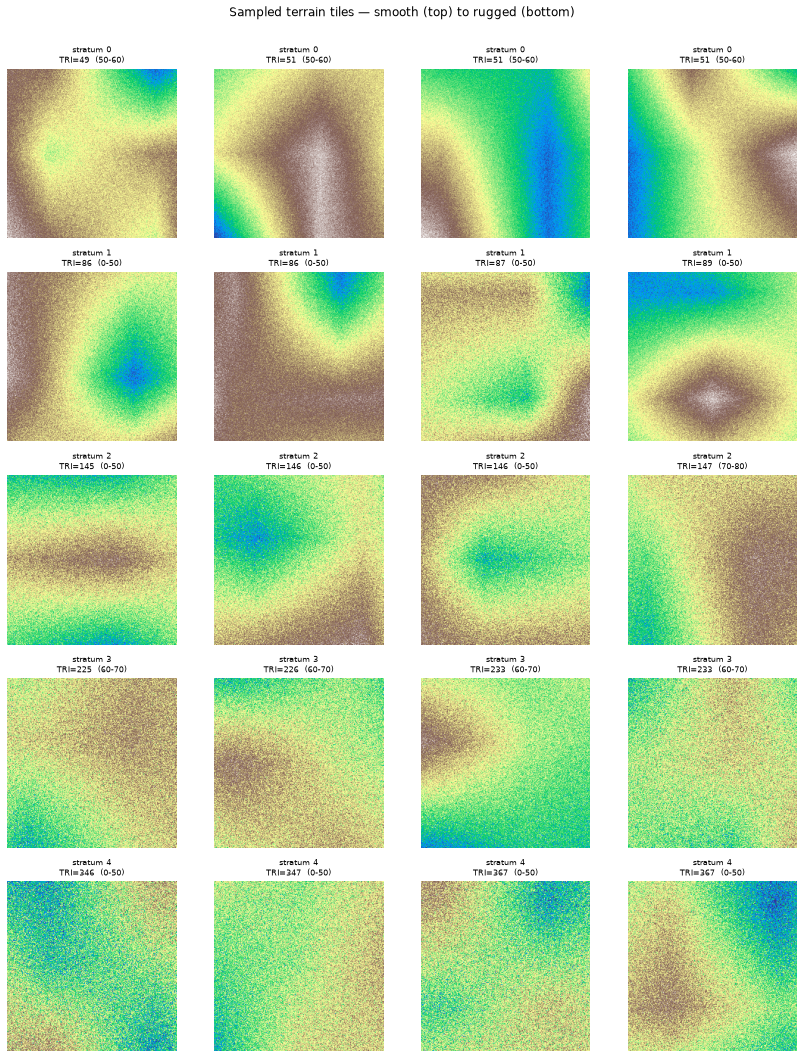

In [3]:
strata = sorted(set(int(s) for s in cols["stratum"]))
per_stratum = 4
fig, axes = plt.subplots(len(strata), per_stratum,
                         figsize=(3 * per_stratum, 3 * len(strata)))
axes = np.atleast_2d(axes)
rng = np.random.default_rng(0)

for r, s in enumerate(strata):
    idx = np.where(cols["stratum"] == s)[0]
    order = idx[np.argsort(cols["tri"][idx])]
    mid = len(order) // 2
    picks = order[max(0, mid - per_stratum // 2): mid - per_stratum // 2 + per_stratum]
    for cax, i in zip(axes[r], picks):
        tile = read_tile(i).astype(np.float32)
        shown = np.where(land_mask(tile), tile, np.nan)
        cax.imshow(shown, cmap="terrain")
        cax.set_title(f"stratum {s}\nTRI={cols['tri'][i]:.0f}  ({cols['lat_band'][i]})",
                      fontsize=8)
        cax.axis("off")
    for cax in axes[r][len(picks):]:
        cax.axis("off")

fig.suptitle("Sampled terrain tiles — smooth (top) to rugged (bottom)", y=1.005)
fig.tight_layout()
plt.show()

## 2 — TRI & stratification distribution

The corpus is stratified by Terrain Ruggedness Index so rugged terrain is
oversampled relative to a geographically uniform draw. **Left:** the TRI
distribution with the quintile cut points (dashed) that define the five
equal-quota strata. **Middle:** tiles per stratum — flat by construction.
**Right:** the geographic spread (lon/lat), colored by stratum.

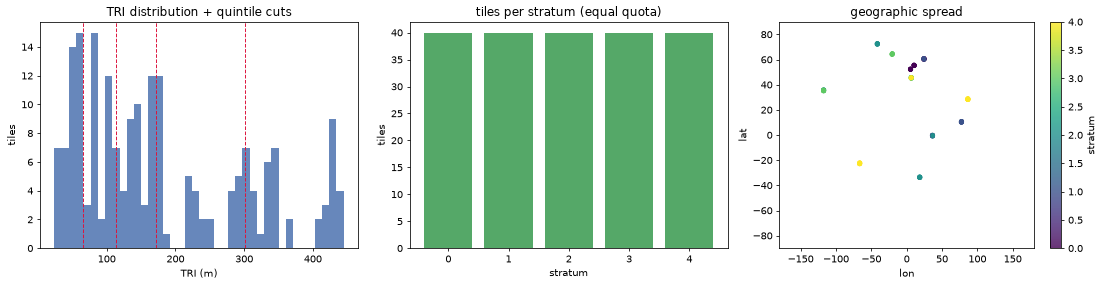

In [4]:
tri = cols["tri"].astype(float)
edges = stratify.quantile_edges(tri, config.N_STRATA)

fig, (ax0, ax1, ax2) = plt.subplots(1, 3, figsize=(16, 4.2))

ax0.hist(tri, bins=40, color="#4c72b0", alpha=0.85)
for e in edges:
    ax0.axvline(e, color="crimson", ls="--", lw=1)
ax0.set(title="TRI distribution + quintile cuts", xlabel="TRI (m)", ylabel="tiles")

counts = [int((cols["stratum"] == s).sum()) for s in strata]
ax1.bar([str(s) for s in strata], counts, color="#55a868")
ax1.set(title="tiles per stratum (equal quota)", xlabel="stratum", ylabel="tiles")

sc = ax2.scatter(cols["lon"], cols["lat"], c=cols["stratum"], cmap="viridis",
                 s=14, alpha=0.8)
ax2.set(title="geographic spread", xlabel="lon", ylabel="lat")
ax2.set_xlim(-180, 180); ax2.set_ylim(-90, 90)
fig.colorbar(sc, ax=ax2, label="stratum")

fig.tight_layout()
plt.show()

## 3 — Before / after per-tile normalization

The default normalization is **per-tile standardization**: subtract the tile's
land-only mean, divide by its land-only std (both stored in the manifest for
inversion). This teaches the model *terrain shape* invariant to absolute altitude.
Each row shows one tile: raw elevation (metres) → normalized (≈ zero-mean,
unit-std over land) → their value histograms.

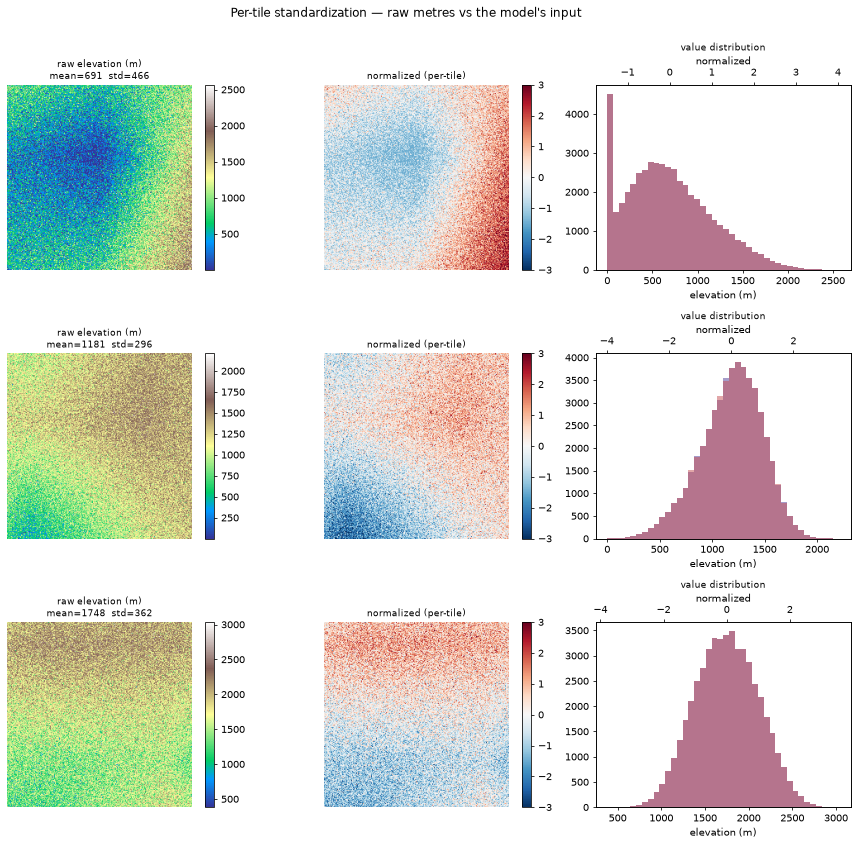

normalized land mean=0.000 std=1.000 (expect ~0, ~1)


In [5]:
normalizer = PerTileNormalizer()
# Pick tiles spanning low → high mean elevation for contrast.
order = np.argsort(cols["mean"])
picks = order[np.linspace(0, len(order) - 1, 3).astype(int)]

fig, axes = plt.subplots(len(picks), 3, figsize=(13, 4 * len(picks)))
axes = np.atleast_2d(axes)

for row, i in enumerate(picks):
    tile = read_tile(i).astype(np.float32)
    mask = land_mask(tile)
    mean, std = float(cols["mean"][i]), float(cols["std"][i])
    norm = normalizer(tile, mean=mean, std=std)

    raw_show = np.where(mask, tile, np.nan)
    norm_show = np.where(mask, norm, np.nan)

    im0 = axes[row, 0].imshow(raw_show, cmap="terrain")
    axes[row, 0].set_title(f"raw elevation (m)\nmean={mean:.0f}  std={std:.0f}", fontsize=9)
    axes[row, 0].axis("off"); fig.colorbar(im0, ax=axes[row, 0], fraction=0.046)

    im1 = axes[row, 1].imshow(norm_show, cmap="RdBu_r", vmin=-3, vmax=3)
    axes[row, 1].set_title("normalized (per-tile)", fontsize=9)
    axes[row, 1].axis("off"); fig.colorbar(im1, ax=axes[row, 1], fraction=0.046)

    axes[row, 2].hist(tile[mask], bins=40, color="#8172b3", alpha=0.7, label="raw (m)")
    ax_t = axes[row, 2].twiny()
    ax_t.hist(norm[mask], bins=40, color="#c44e52", alpha=0.5, label="normalized")
    axes[row, 2].set_title("value distribution", fontsize=9)
    axes[row, 2].set_xlabel("elevation (m)"); ax_t.set_xlabel("normalized")

fig.suptitle("Per-tile standardization — raw metres vs the model's input", y=1.002)
fig.tight_layout()
plt.show()

# Sanity check: normalized land pixels are ~zero-mean, ~unit-std.
i = int(picks[-1])
tile = read_tile(i).astype(np.float32)
mask = land_mask(tile)
norm = normalizer(tile, mean=float(cols["mean"][i]), std=float(cols["std"][i]))
print("normalized land mean=%.3f std=%.3f (expect ~0, ~1)" % (norm[mask].mean(), norm[mask].std()))

---

**Reproduce this:** the synthetic sample is fully deterministic —
`python -m dataset.build --source synthetic` rebuilds the identical corpus
(same `dataset_version`) on any machine with zero network. To visualize the real
Phase-0 debug corpus, run `python -m dataset.build --source live` (see the
Dockerfile for the pinned environment) and set `CORPUS_DIR = Path("data/corpus")`
above.